In [221]:
import pandas as pd
import numpy as np

import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error



import matplotlib.pyplot as subplots
import missingno as msno



# from sklearn.model_selection import train_test_split we would've used
# this if we automated our data seperation

In [222]:
data = pd.read_csv('./TIA-WEATHER-DATA-2015-01-01-TO-2025-06-30.csv')
data.columns

Index(['datetime', 'tempmax', 'tempmin', 'temp', 'dew', 'humidity',
       'precipprob', 'precipcover', 'preciptype', 'windgust', 'windspeed',
       'winddir', 'sealevelpressure', 'cloudcover', 'visibility',
       'solarradiation', 'solarenergy', 'uvindex', 'severerisk', 'sunrise',
       'sunset', 'precipitation'],
      dtype='str')

In [223]:
data[0:10]

,datetime,tempmax,tempmin,temp,dew,humidity,precipprob,precipcover,preciptype,windgust,...,sealevelpressure,cloudcover,visibility,solarradiation,solarenergy,uvindex,severerisk,sunrise,sunset,precipitation
0,2015-01-01,60.7,39.1,50.0,41.7,74.7,100,4.17,rain,11.2,...,1020.4,79.1,2.4,96.6,8.3,4,NaN,2015-01-01T06:54:15,2015-01-01T17:19:31,0.8
1,2015-01-02,71.0,49.9,54.9,48.4,80.1,100,20.83,rain,19.9,...,1022.2,93.3,2.9,40.4,3.3,2,NaN,2015-01-02T06:54:31,2015-01-02T17:20:12,0.0
2,2015-01-03,67.7,48.1,54.8,50.5,86.3,100,8.33,rain,15.4,...,1021.0,90.3,2.8,58.6,5.0,4,NaN,2015-01-03T06:54:46,2015-01-03T17:20:54,0.5
3,2015-01-04,69.9,48.1,54.5,49.6,85.5,100,4.17,rain,17.0,...,1018.1,67.1,2.7,118.0,10.3,6,NaN,2015-01-04T06:54:58,2015-01-04T17:21:37,0.5
4,2015-01-05,64.3,42.7,51.3,45.7,83.2,0,0.00,NaN,16.3,...,1013.9,41.6,3.9,139.2,12.0,6,NaN,2015-01-05T06:55:10,2015-01-05T17:22:20,0.0
5,2015-01-06,62.5,46.3,52.2,45.0,78.0,0,0.00,NaN,16.1,...,1016.4,62.5,3.7,98.8,8.5,5,NaN,2015-01-06T06:55:20,2015-01-06T17:23:04,0.0
6,2015-01-07,60.7,43.4,50.3,43.1,77.8,0,0.00,NaN,15.7,...,1017.1,65.7,3.4,102.8,8.9,5,NaN,2015-01-07T06:55:28,2015-01-07T17:23:49,0.0
7,2015-01-08,71.7,39.1,49.3,41.5,76.4,100,4.17,rain,15.7,...,1018.9,50.1,3.9,114.1,9.7,5,NaN,2015-01-08T06:55:35,2015-01-08T17:24:34,0.0
8,2015-01-09,64.3,39.1,48.4,38.7,72.8,0,0.00,NaN,15.4,...,1020.3,24.0,3.8,173.6,14.8,7,NaN,2015-01-09T06:55:40,2015-01-09T17:25:20,0.0
9,2015-01-10,67.9,35.5,47.9,35.7,68.2,0,0.00,NaN,12.1,...,1018.8,22.9,3.9,190.1,16.2,7,NaN,2015-01-10T06:55:44,2015-01-10T17:26:06,0.0


In [224]:
data.dtypes 

datetime                str
tempmax             float64
tempmin             float64
temp                float64
dew                 float64
humidity            float64
precipprob            int64
precipcover         float64
preciptype              str
windgust            float64
windspeed           float64
winddir             float64
sealevelpressure    float64
cloudcover          float64
visibility          float64
solarradiation      float64
solarenergy         float64
uvindex               int64
severerisk          float64
sunrise                 str
sunset                  str
precipitation       float64
dtype: object

In [225]:
columns_to_keep = ['datetime', 'humidity','precipitation','tempmax','tempmin','temp', 'cloudcover','solarenergy']

new_df = data[columns_to_keep]

new_df[:10]

,datetime,humidity,precipitation,tempmax,tempmin,temp,cloudcover,solarenergy
0,2015-01-01,74.7,0.8,60.7,39.1,50.0,79.1,8.3
1,2015-01-02,80.1,0.0,71.0,49.9,54.9,93.3,3.3
2,2015-01-03,86.3,0.5,67.7,48.1,54.8,90.3,5.0
3,2015-01-04,85.5,0.5,69.9,48.1,54.5,67.1,10.3
4,2015-01-05,83.2,0.0,64.3,42.7,51.3,41.6,12.0
5,2015-01-06,78.0,0.0,62.5,46.3,52.2,62.5,8.5
6,2015-01-07,77.8,0.0,60.7,43.4,50.3,65.7,8.9
7,2015-01-08,76.4,0.0,71.7,39.1,49.3,50.1,9.7
8,2015-01-09,72.8,0.0,64.3,39.1,48.4,24.0,14.8
9,2015-01-10,68.2,0.0,67.9,35.5,47.9,22.9,16.2


In [226]:
new_df.dtypes

datetime             str
humidity         float64
precipitation    float64
tempmax          float64
tempmin          float64
temp             float64
cloudcover       float64
solarenergy      float64
dtype: object

In [227]:
new_df['datetime'] = pd.to_datetime(new_df['datetime'])

In [228]:
import pandas as pd

stats = new_df.describe()

print(stats)

                         datetime     humidity  precipitation      tempmax  \
count                        3468  3468.000000    3468.000000  3468.000000   
mean   2020-09-11 09:33:00.622837    75.141984       4.088041    76.085294   
min           2015-01-01 00:00:00    25.200000       0.000000    48.100000   
25%           2018-05-17 18:00:00    69.400000       0.000000    69.700000   
50%           2020-09-30 12:00:00    76.200000       0.000000    76.900000   
75%           2023-02-14 06:00:00    83.300000       2.422300    82.300000   
max           2025-06-30 00:00:00   100.000000     164.300000   102.100000   
std                           NaN    11.479143      10.769362     7.789576   

           tempmin         temp   cloudcover  solarenergy  
count  3468.000000  3468.000000  3468.000000  3468.000000  
mean     57.193829    65.385265    47.204123    15.997030  
min      32.100000    44.000000    18.800000     0.000000  
25%      48.100000    57.175000    25.000000    12.900000

In [229]:
import pandas as pd

# 1. Generate your full timeline
expected_dates = pd.date_range(start=new_df.index.min(), end=new_df.index.max(), freq='D')

# 2. Extract all missing dates
missing_dates = expected_dates.difference(new_df.index)

# 3. Print the exact start and end boundaries of the gap
if not missing_dates.empty:
    print(f"Data is missing FROM: {missing_dates.min().strftime('%Y-%m-%d')}")
    print(f"Data is missing UNTIL: {missing_dates.max().strftime('%Y-%m-%d')}")
    print(f"Total duration of the gap: {len(missing_dates)} days")
else:
    print("No missing data entries found!")


Data is missing FROM: 1970-01-01
Data is missing UNTIL: 1970-01-01
Total duration of the gap: 1 days


In [230]:
new_df = new_df.set_index('datetime')

In [231]:
new_df.isnull().sum()

humidity         0
precipitation    0
tempmax          0
tempmin          0
temp             0
cloudcover       0
solarenergy      0
dtype: int64

In [232]:
new_df[180:365]

,humidity,precipitation,tempmax,tempmin,temp,cloudcover,solarenergy
datetime,,,,,,,
2015-06-30,80.2,0.0,92.0,68.6,76.5,73.9,18.2
2016-07-01,96.8,53.1,71.5,67.9,69.9,97.0,4.6
2016-07-02,93.9,13.7,80.5,67.9,71.0,91.0,8.9
2016-07-03,88.4,2.0,84.1,69.7,73.8,86.3,12.5
2016-07-04,84.5,16.8,80.5,69.7,74.7,85.3,13.0
...,...,...,...,...,...,...,...
2016-12-27,74.0,0.0,66.1,40.9,52.2,27.1,14.9
2016-12-28,79.1,0.0,64.3,40.9,51.3,30.2,14.6
2016-12-29,79.4,0.0,64.3,40.9,51.0,31.3,14.1


In [233]:
expected_dates = pd.date_range(start=new_df.index.min(), end=new_df.index.max())
missing_dates = expected_dates.difference(new_df.index)
missing_dates

print(missing_dates);

DatetimeIndex(['2015-07-01', '2015-07-02', '2015-07-03', '2015-07-04',
               '2015-07-05', '2015-07-06', '2015-07-07', '2015-07-08',
               '2015-07-09', '2015-07-10',
               ...
               '2016-06-21', '2016-06-22', '2016-06-23', '2016-06-24',
               '2016-06-25', '2016-06-26', '2016-06-27', '2016-06-28',
               '2016-06-29', '2016-06-30'],
              dtype='datetime64[us]', length=366, freq='D')


In [234]:


# 1. Generate the perfect continuous datetime timeline
ideal_index = pd.date_range(start=new_df.index.min(), end=new_df.index.max(), freq='D')

# 2. Reindex new_df to force missing timestamps into true empty rows
reindexed_df = new_df.reindex(ideal_index)

# 3. Target the reindexed index to look for missing entries
is_null_series = reindexed_df.index.to_series().isnull()

# 4. Group and calculate the size of consecutive true/false missing blocks
block_groups = (is_null_series != is_null_series.shift()).cumsum()
blocks = is_null_series.groupby(block_groups).size()
missing_lengths = blocks[is_null_series.groupby(block_groups).first()]

# 5. Output the final summary table
print("Frequency of missing datetime block sizes:")
print(missing_lengths.value_counts())


Frequency of missing datetime block sizes:
Series([], Name: count, dtype: int64)


In [235]:
import pandas as pd

# 1. Generate your full timeline
expected_dates = pd.date_range(start=new_df.index.min(), end=new_df.index.max(), freq='D')

# 2. Extract all missing dates
missing_dates = expected_dates.difference(new_df.index)

# 3. Print the exact start and end boundaries of the gap
if not missing_dates.empty:
    print(f"Data is missing FROM: {missing_dates.min().strftime('%Y-%m-%d')}")
    print(f"Data is missing UNTIL: {missing_dates.max().strftime('%Y-%m-%d')}")
    print(f"Total duration of the gap: {len(missing_dates)} days")
else:
    print("No missing data entries found!")


new_df[0:-1]

Data is missing FROM: 2015-07-01
Data is missing UNTIL: 2016-06-30
Total duration of the gap: 366 days


,humidity,precipitation,tempmax,tempmin,temp,cloudcover,solarenergy
datetime,,,,,,,
2015-01-01,74.7,0.8000,60.7,39.1,50.0,79.1,8.3
2015-01-02,80.1,0.0000,71.0,49.9,54.9,93.3,3.3
2015-01-03,86.3,0.5000,67.7,48.1,54.8,90.3,5.0
2015-01-04,85.5,0.5000,69.9,48.1,54.5,67.1,10.3
2015-01-05,83.2,0.0000,64.3,42.7,51.3,41.6,12.0
...,...,...,...,...,...,...,...
2025-06-25,86.1,8.9000,82.3,69.7,75.5,81.7,19.0
2025-06-26,85.9,9.9000,84.1,71.5,76.7,75.9,26.1
2025-06-27,84.0,18.8000,82.3,69.7,76.7,80.1,23.1


In [236]:
new_df.columns

Index(['humidity', 'precipitation', 'tempmax', 'tempmin', 'temp', 'cloudcover',
       'solarenergy'],
      dtype='str')

<Axes: >

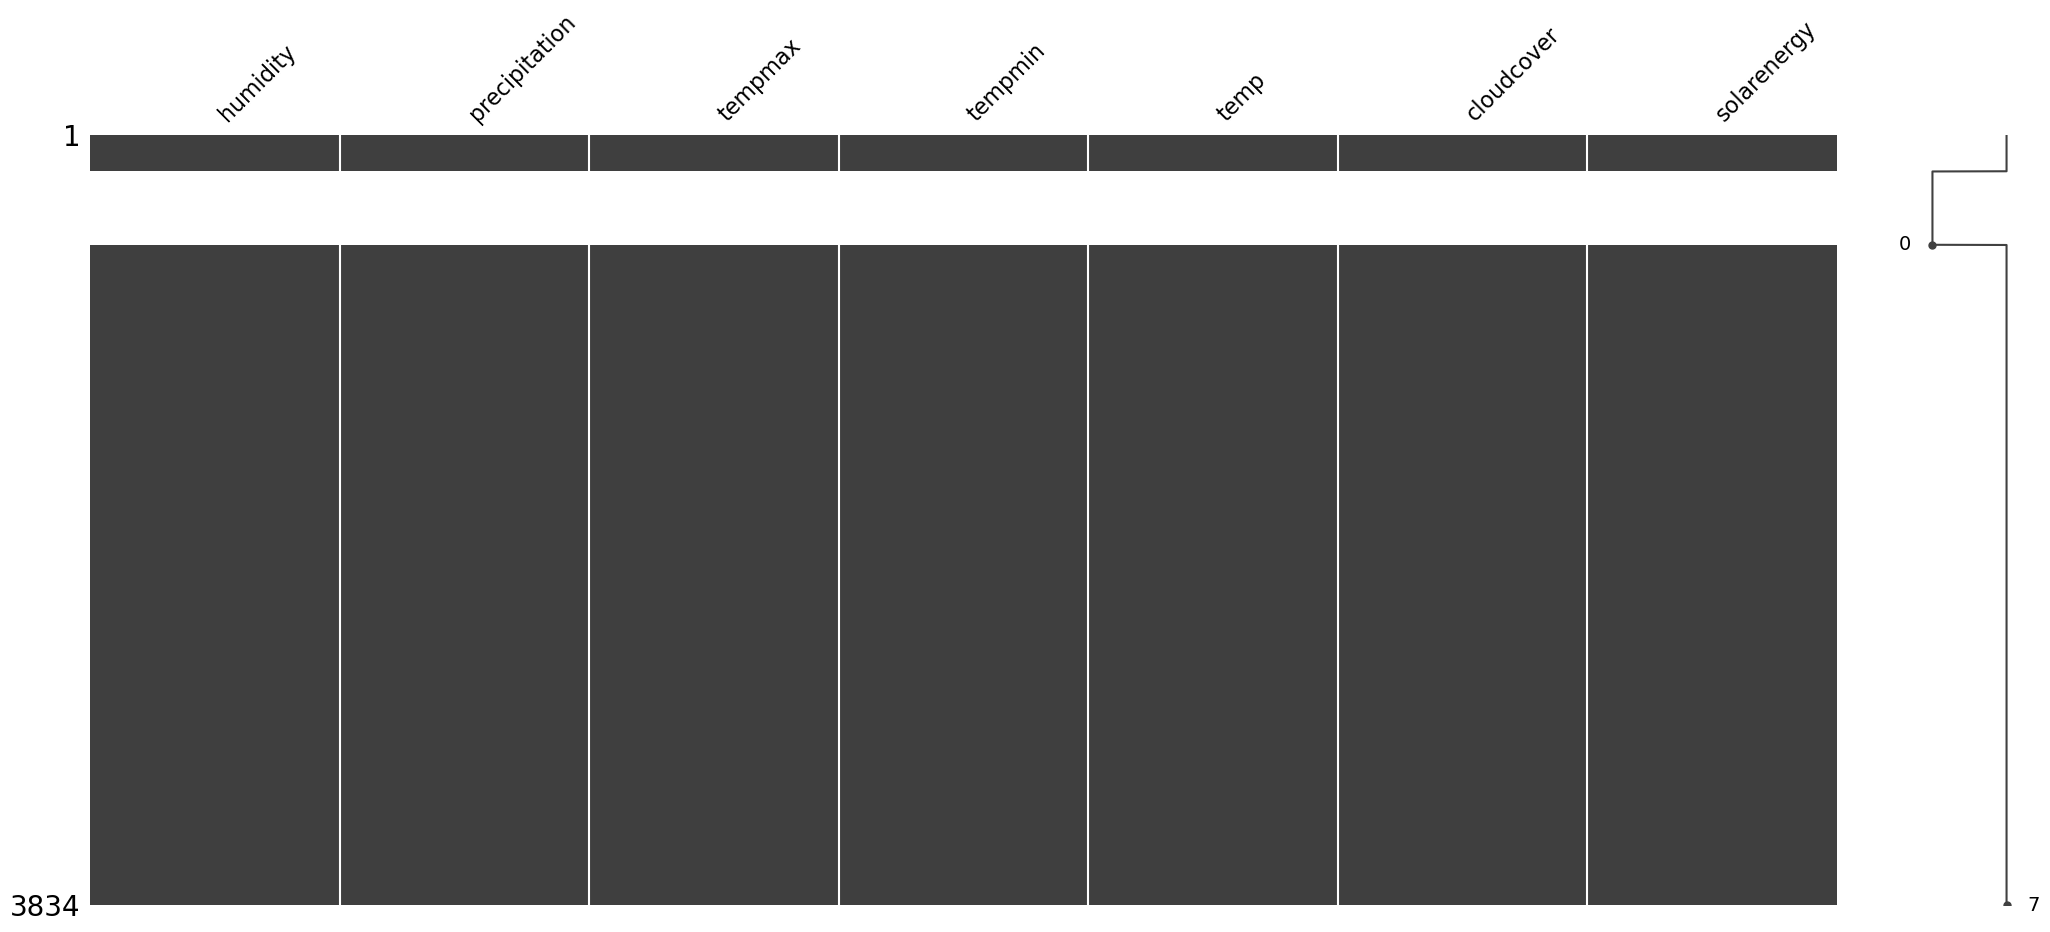

In [237]:
import missingno as msno
import missingno as msno

# Make sure you are plotting the reindexed dataframe to see the timeline gap
msno.matrix(new_df.reindex(pd.date_range(start=new_df.index.min(), end=new_df.index.max(), freq='D')))


In [238]:
predictor_columns = ['humidity', 'tempmax', 'tempmin', 'temp', 'cloudcover',  'solarenergy']

target =  'precipitation'

In [239]:
# Keep the DataFrame sorted chronologically
new_df = new_df.sort_index()

X = new_df[predictor_columns]
y = new_df[target]

# Train on the older, historical data (approx. 9 years)
X_train = X.loc['2015-01-01':'2024-06-30']
y_train = y.loc['2015-01-01':'2024-06-30']

# Test on the most recent data (1 Year)
X_test = X.loc['2024-07-01':'2025-06-29']
y_test = y.loc['2024-07-01':'2025-06-29']


In [247]:
model =xgb.XGBRegressor(n_estimators=500,learning_rate = 1,random_state=42)

In [241]:
model.fit(X_train,y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes

In [242]:
predictions = model.predict(X_test)


In [248]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 2. Run your evaluation calculations
rmse = np.sqrt(mean_squared_error(y_test, predictions))
mae = mean_absolute_error(y_test, predictions)

# 3. Print the results to your screen
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")

Root Mean Squared Error (RMSE): 13.4769
Mean Absolute Error (MAE): 5.3280


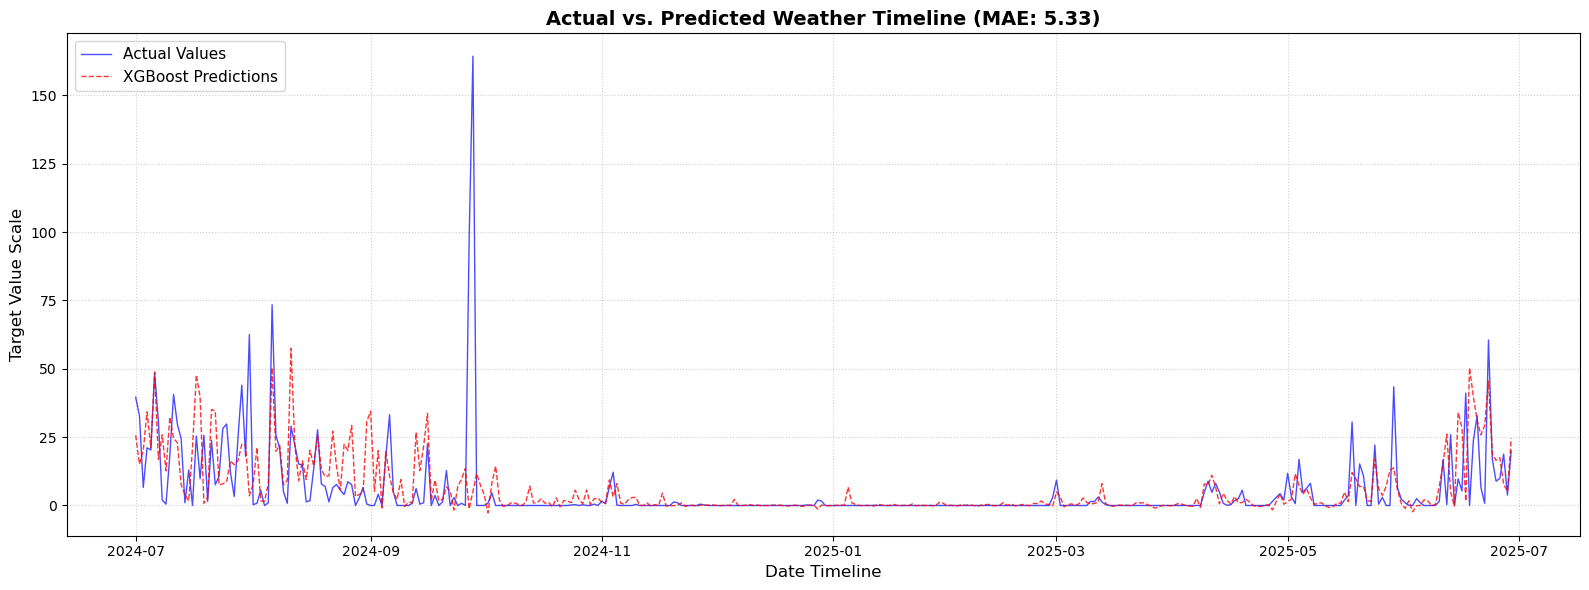

In [249]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Set up the plotting canvas size (Width=12 inches, Height=6 inches)
plt.figure(figsize=(16, 6))

# 2. Plot the true actual values (Blue line)
# We use y_test.index as the X-axis timeline
plt.plot(y_test.index, y_test.values, label='Actual Values', color='blue', alpha=0.7, linewidth=1)

# 3. Plot the model's predictions (Red dashed line)
plt.plot(y_test.index, predictions, label='XGBoost Predictions', color='red', linestyle='--', alpha=0.8, linewidth=1)

# 4. Add clear descriptions and labels
plt.title(f'Actual vs. Predicted Weather Timeline (MAE: {mae:.2f})', fontsize=14, fontweight='bold')
plt.xlabel('Date Timeline', fontsize=12)
plt.ylabel('Target Value Scale', fontsize=12)

# 5. Add a legend so we know which line is which
plt.legend(fontsize=11, loc='upper left')

# 6. Clean up the layout and display the plot
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


In [245]:
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, mean_absolute_error

# Convert arrays into a single, clean Pandas DataFrame for easy filtering
eval_df = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': predictions
}, index=y_test.index)

# Define a tiny threshold because regression models rarely predict exactly 0.0000
# If the prediction is greater than 0.1, we classify it as a "Predicted Rain Day"
threshold = 0.1

eval_df['Actual_Rain'] = eval_df['Actual'] > 0.0
eval_df['Predicted_Rain'] = eval_df['Predicted'] > threshold

# ---------------------------------------------------------------------------
# QUESTION 1: "When the model said it was going to rain, did it?" (Precision)
# ---------------------------------------------------------------------------
# Filter to look ONLY at days where the model predicted rain
predicted_rain_days = eval_df[eval_df['Predicted_Rain'] == True]

if len(predicted_rain_days) > 0:
    # Calculate how many of those predicted days actually had rain
    actually_rained_count = predicted_rain_days['Actual_Rain'].sum()
    precision = (actually_rained_count / len(predicted_rain_days)) * 100
else:
    precision = 0.0

# ---------------------------------------------------------------------------
# QUESTION 2: "When it did rain, how accurate was the amount?" (Conditional MAE)
# ---------------------------------------------------------------------------
# Filter to look ONLY at days where it actually rained in the real world
actual_rain_days = eval_df[eval_df['Actual_Rain'] == True]

if len(actual_rain_days) > 0:
    rain_amount_mae = mean_absolute_error(actual_rain_days['Actual'], actual_rain_days['Predicted'])
else:
    rain_amount_mae = 0.0

# ---------------------------------------------------------------------------
# PRINT THE LESSON RESULTS
# ---------------------------------------------------------------------------
print("=== QUESTION 1: RAIN DETECTION ACCURACY ===")
print(f"The model predicted rain on {len(predicted_rain_days)} days.")
print(f"Out of those days, it actually rained on {actually_rained_count} days.")
print(f"👉 Precision Score: {precision:.2f}% of the time the model said 'Rain', it was correct.")
print("\n" + "="*43)
print("=== QUESTION 2: RAIN AMOUNT ACCURACY ===")
print(f"There were {len(actual_rain_days)} actual rainy days in the test set.")
print(f"👉 Rainy Day MAE: On days it actually rained, the model missed the amount by an average of {rain_amount_mae:.2f} units.")


=== QUESTION 1: RAIN DETECTION ACCURACY ===
The model predicted rain on 253 days.
Out of those days, it actually rained on 142 days.
👉 Precision Score: 56.13% of the time the model said 'Rain', it was correct.

=== QUESTION 2: RAIN AMOUNT ACCURACY ===
There were 156 actual rainy days in the test set.
👉 Rainy Day MAE: On days it actually rained, the model missed the amount by an average of 10.21 units.


In [246]:
'''
If you are predicting smooth, continuous variables (Temperatures, Cloud Cover, Solar Energy) → Use RMSE.
If you are predicting spiky, zero-heavy variables (Precipitation / Rain) → Use MAE.
'''

'\nIf you are predicting smooth, continuous variables (Temperatures, Cloud Cover, Solar Energy) → Use RMSE.\nIf you are predicting spiky, zero-heavy variables (Precipitation / Rain) → Use MAE.\n'